# 4 — Large-scale stability diagnostics

This experiment samples 5,000 recurrent trees and measures numerical explosions, near-zero tails, and nearly constant trajectories across horizons and initial-value ranges.

## 1. Configuração completa e reprodutibilidade

A gramática é a mesma família usada nos notebooks anteriores, agora com até seis operadores e apenas uma série, para permitir execução univariada. O terminal de tempo é desabilitado nesta análise para que crescimento determinístico em `t` não se confunda com instabilidade da recorrência.


In [1]:
from __future__ import annotations

from collections import Counter
from dataclasses import asdict
from pathlib import Path
import importlib.metadata
import json
import platform
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "tsfmxai").exists():
            return candidate
    raise RuntimeError("Repository root not found.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SOURCE_ROOT = PROJECT_ROOT / "src"
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

from tsfmxai.generators import (
    RandomTreeConfig,
    derive_sample_seed,
    evaluate_bound_expression,
    required_history_length,
    sample_random_mechanisms,
)
from tsfmxai.representations import (
    Add,
    Lag,
    Multiply,
    Parameter,
    Time,
    operator_count,
    parameter_slots,
    lag_slots,
    to_skeleton_formula,
    tree_depth,
    walk,
)

ROOT_SEED = 20261001
SAMPLE_COUNT = 5_000
GENERATED_HORIZONS = (96, 192, 384)
REFERENCE_HORIZON = 192
INNOVATION_STD = 0.05
ZERO_RADIUS_INNOVATION_STDS = 3.0
ZERO_TAIL_STEPS = 24
ZERO_RADIUS = ZERO_RADIUS_INNOVATION_STDS * INNOVATION_STD
INPUT_ABS_LIMITS = (0.0, 0.1, 0.5, 1.0, 2.0)
EXPLOSION_LIMIT = 100.0

TREE_CONFIG = RandomTreeConfig(
    minimum_operators=1,
    maximum_operators=6,
    num_series=1,
    minimum_lag=1,
    maximum_lag=12,
    parameter_probability=0.55,
    time_probability=0.0,
    lag_probability=0.45,
    add_probability=0.80,
    minimum_parameter_magnitude=0.05,
    maximum_parameter_magnitude=0.80,
    require_lag=True,
    require_time=False,
)

print(json.dumps({
    "root_seed": ROOT_SEED,
    "sample_count": SAMPLE_COUNT,
    "generated_horizons": GENERATED_HORIZONS,
    "innovation_std": INNOVATION_STD,
    "zero_radius": ZERO_RADIUS,
    "zero_tail_steps": ZERO_TAIL_STEPS,
    "input_absolute_limits": INPUT_ABS_LIMITS,
    "explosion_limit": EXPLOSION_LIMIT,
    "tree_config": asdict(TREE_CONFIG),
}, indent=2))

{
  "root_seed": 20261001,
  "sample_count": 5000,
  "generated_horizons": [
    96,
    192,
    384
  ],
  "innovation_std": 0.05,
  "zero_radius": 0.15000000000000002,
  "zero_tail_steps": 24,
  "input_absolute_limits": [
    0.0,
    0.1,
    0.5,
    1.0,
    2.0
  ],
  "explosion_limit": 100.0,
  "tree_config": {
    "minimum_operators": 1,
    "maximum_operators": 6,
    "num_series": 1,
    "minimum_lag": 1,
    "maximum_lag": 12,
    "parameter_probability": 0.55,
    "time_probability": 0.0,
    "lag_probability": 0.45,
    "add_probability": 0.8,
    "minimum_parameter_magnitude": 0.05,
    "maximum_parameter_magnitude": 0.8,
    "require_lag": true,
    "require_time": false,
    "coefficient_gate_lags": false
  }
}


## 2. Amostrar milhares de mecanismos

Cada índice recebe uma semente derivada de `(ROOT_SEED, índice)`. Assim, aumentar a quantidade de amostras ou mudar a ordem de execução não altera os mecanismos já associados aos índices anteriores.


In [2]:
sampling_started = time.perf_counter()
mechanisms = sample_random_mechanisms(
    TREE_CONFIG,
    root_seed=ROOT_SEED,
    count=SAMPLE_COUNT,
)
sampling_seconds = time.perf_counter() - sampling_started

assert len(mechanisms) == SAMPLE_COUNT
assert mechanisms[:20] == sample_random_mechanisms(
    TREE_CONFIG, root_seed=ROOT_SEED, count=20
)
print(f"Mecanismos gerados: {len(mechanisms):,}")
print(f"Tempo de amostragem: {sampling_seconds:.3f} s")

Mecanismos gerados: 5,000
Tempo de amostragem: 1.880 s


## 3. Structure of the sampled mechanisms

Count operators, lags, and parameter ranges before simulating the trajectories.

In [3]:
structure_rows = []
for mechanism in mechanisms:
    nodes = list(walk(mechanism.expression))
    parameters = tuple(mechanism.binding.parameter_values.values())
    structure_rows.append({
        "sample_index": mechanism.sample_index,
        "formula": mechanism.formula,
        "operator_count": operator_count(mechanism.expression),
        "tree_depth": tree_depth(mechanism.expression),
        "multiply_count": sum(isinstance(node, Multiply) for node in nodes),
        "lag_count": len(lag_slots(mechanism.expression)),
        "parameter_count": len(parameter_slots(mechanism.expression)),
        "max_abs_parameter": max(map(abs, parameters), default=0.0),
    })
structure = pd.DataFrame(structure_rows)
display(structure.describe())

,sample_index,operator_count,tree_depth,multiply_count,lag_count,parameter_count,max_abs_parameter
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2499.500000,3.540200,4.111600,0.707800,2.163000,2.377200,0.524428
std,1443.520003,1.709552,1.412921,0.826169,1.176056,1.400183,0.226831
min,0.000000,1.000000,2.000000,0.000000,1.000000,0.000000,0.000000
25%,1249.750000,2.000000,3.000000,0.000000,1.000000,1.000000,0.386313
50%,2499.500000,4.000000,4.000000,1.000000,2.000000,2.000000,0.588332
75%,3749.250000,5.000000,5.000000,1.000000,3.000000,3.000000,0.710416
max,4999.000000,6.000000,7.000000,5.000000,7.000000,6.000000,0.799957


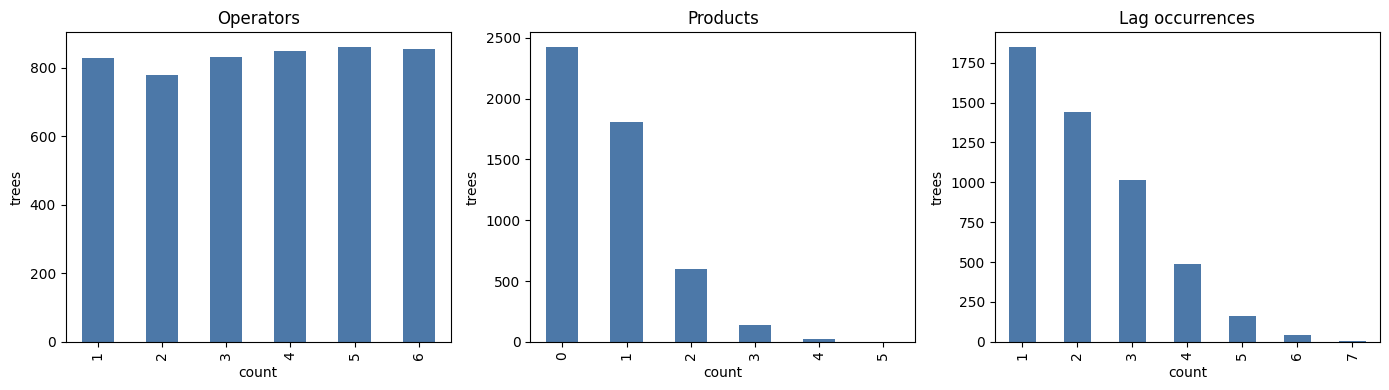

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column, title in zip(
    axes,
    ("operator_count", "multiply_count", "lag_count"),
    ("Operators", "Products", "Lag occurrences"),
):
    structure[column].value_counts().sort_index().plot.bar(ax=ax, color="#4C78A8")
    ax.set(title=title, xlabel="count", ylabel="trees")
fig.tight_layout()
plt.show()

## 4. Simulação pareada com limites de entrada

Para cada mecanismo, primeiro é sorteado um vetor-base em `[-1, 1]`. Esse vetor é multiplicado por cada limite solicitado. As inovações gaussianas são idênticas entre limites para o mesmo mecanismo. Registramos o primeiro passo que cruza o limite, o maior módulo observado antes da parada e o motivo da explosão. Uma trajetória é classificada como `proxima_de_zero` quando não explode e **todos os seus 24 últimos valores gerados** permanecem a no máximo três desvios-padrão das inovações em relação a zero: `|x_t| <= 3 * 0.05 = 0.15`. Uma série é `constante_em_3_inovacoes` quando **todos os valores gerados** permanecem a no máximo três desvios-padrão das inovações de seu nível médio: `max(|x_t - mean(x)|) <= 0.15`. O histórico inicial é desconsiderado e séries explosivas não são constantes.


In [5]:
def simulate_with_input_limit(mechanism, input_abs_limit: float, generated_horizon: int) -> dict:
    history_length = required_history_length(mechanism.expression, mechanism.binding)
    sequence = np.random.SeedSequence([ROOT_SEED, int(mechanism.sample_index), 991])
    initialization_sequence, innovation_sequence = sequence.spawn(2)
    initialization_rng = np.random.default_rng(initialization_sequence)
    innovation_rng = np.random.default_rng(innovation_sequence)
    initial_values = initialization_rng.uniform(-1.0, 1.0, size=history_length) * input_abs_limit
    innovations = innovation_rng.normal(0.0, INNOVATION_STD, size=generated_horizon)
    values = list(map(float, initial_values))
    generated_values = []
    peak_abs = float(np.max(np.abs(initial_values))) if history_length else 0.0

    for step in range(generated_horizon):
        current_time = history_length + step
        next_value = evaluate_bound_expression(
            mechanism.expression,
            mechanism.binding,
            time=current_time,
            histories={0: values},
        ) + float(innovations[step])
        if not np.isfinite(next_value):
            return {"exploded": True, "near_zero": False, "constant_within_3sigma": False, "max_constant_deviation": np.nan, "zero_tail_peak_abs": np.nan, "explosion_step": step + 1, "reason": "non_finite", "peak_abs": np.inf}
        peak_abs = max(peak_abs, abs(next_value))
        if abs(next_value) > EXPLOSION_LIMIT:
            return {"exploded": True, "near_zero": False, "constant_within_3sigma": False, "max_constant_deviation": np.nan, "zero_tail_peak_abs": np.nan, "explosion_step": step + 1, "reason": "magnitude", "peak_abs": peak_abs}
        values.append(float(next_value))
        generated_values.append(float(next_value))
    zero_tail_peak_abs = float(np.max(np.abs(values[-ZERO_TAIL_STEPS:])))
    near_zero = zero_tail_peak_abs <= ZERO_RADIUS
    generated_array = np.asarray(generated_values)
    constant_level = float(np.mean(generated_array))
    max_constant_deviation = float(np.max(np.abs(generated_array - constant_level)))
    constant_within_3sigma = max_constant_deviation <= ZERO_RADIUS
    return {"exploded": False, "near_zero": near_zero, "constant_within_3sigma": constant_within_3sigma, "max_constant_deviation": max_constant_deviation, "zero_tail_peak_abs": zero_tail_peak_abs, "explosion_step": np.nan, "reason": "stable", "peak_abs": peak_abs}


simulation_started = time.perf_counter()
simulation_rows = []
for generated_horizon in GENERATED_HORIZONS:
    for input_abs_limit in INPUT_ABS_LIMITS:
        for mechanism in mechanisms:
            simulation_rows.append({
                "sample_index": mechanism.sample_index,
                "generated_horizon": generated_horizon,
                "input_abs_limit": input_abs_limit,
                **simulate_with_input_limit(mechanism, input_abs_limit, generated_horizon),
            })
        print(f"Concluído: horizonte={generated_horizon}, |x_inicial| <= {input_abs_limit:g}")

simulation_seconds = time.perf_counter() - simulation_started
simulations = pd.DataFrame(simulation_rows).merge(structure, on="sample_index", validate="many_to_one")
assert len(simulations) == SAMPLE_COUNT * len(INPUT_ABS_LIMITS) * len(GENERATED_HORIZONS)
reference_simulations = simulations[simulations["generated_horizon"].eq(REFERENCE_HORIZON)].copy()
print(f"Simulações: {len(simulations):,} em {simulation_seconds:.2f} s")

Concluído: horizonte=96, |x_inicial| <= 0


Concluído: horizonte=96, |x_inicial| <= 0.1


Concluído: horizonte=96, |x_inicial| <= 0.5


Concluído: horizonte=96, |x_inicial| <= 1


Concluído: horizonte=96, |x_inicial| <= 2


...

Concluído: horizonte=384, |x_inicial| <= 0.1


Concluído: horizonte=384, |x_inicial| <= 0.5


Concluído: horizonte=384, |x_inicial| <= 1


Concluído: horizonte=384, |x_inicial| <= 2


Simulações: 75,000 em 72.84 s


In [6]:
explosion_summary = simulations.groupby(["generated_horizon", "input_abs_limit"]).agg(
    mecanismos=("sample_index", "size"),
    explosões=("exploded", "sum"),
    próximas_de_zero=("near_zero", "sum"),
    séries_constantes_em_3_inovações=("constant_within_3sigma", "sum"),
    taxa_de_explosão=("exploded", "mean"),
    taxa_próximas_de_zero=("near_zero", "mean"),
    passo_mediano_da_explosão=("explosion_step", "median"),
    pico_mediano=("peak_abs", "median"),
)
explosion_summary["estáveis"] = explosion_summary["mecanismos"] - explosion_summary["explosões"]
explosion_summary["taxa_próximas_entre_estáveis"] = (
    explosion_summary["próximas_de_zero"] / explosion_summary["estáveis"]
)

# Wilson 95% interval for each binomial explosion rate.
z = 1.959963984540054
n = explosion_summary["mecanismos"].to_numpy()
p = explosion_summary["taxa_de_explosão"].to_numpy()
center = (p + z*z/(2*n)) / (1 + z*z/n)
half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
explosion_summary["IC95_inferior"] = center - half
explosion_summary["IC95_superior"] = center + half
horizon_tables = {
    horizon: explosion_summary.xs(horizon, level="generated_horizon")
    for horizon in GENERATED_HORIZONS
}
for horizon, table in horizon_tables.items():
    print(f"Horizonte de geração: {horizon} pontos")
    display(table)


Horizonte de geração: 96 pontos


,mecanismos,explosões,próximas_de_zero,séries_constantes_em_3_inovações,taxa_de_explosão,taxa_próximas_de_zero,passo_mediano_da_explosão,pico_mediano,estáveis,taxa_próximas_entre_estáveis,IC95_inferior,IC95_superior
input_abs_limit,,,,,,,,,,,,
0.0,5000,2082,570,571,0.4164,0.1140,37.0,15.653820,2918,0.195339,0.402805,0.430123
0.1,5000,2103,568,554,0.4206,0.1136,37.0,16.315774,2897,0.196065,0.406983,0.434339
0.5,5000,2196,560,322,0.4392,0.1120,35.0,20.200659,2804,0.199715,0.425496,0.452998
1.0,5000,2306,514,166,0.4612,0.1028,33.0,27.069237,2694,0.190794,0.447418,0.475042
2.0,5000,2552,376,76,0.5104,0.0752,27.0,100.687707,2448,0.153595,0.496541,0.524243


Horizonte de geração: 192 pontos


,mecanismos,explosões,próximas_de_zero,séries_constantes_em_3_inovações,taxa_de_explosão,taxa_próximas_de_zero,passo_mediano_da_explosão,pico_mediano,estáveis,taxa_próximas_entre_estáveis,IC95_inferior,IC95_superior
input_abs_limit,,,,,,,,,,,,
0.0,5000,2357,569,354,0.4714,0.1138,41.0,48.165473,2643,0.215286,0.457591,0.485253
0.1,5000,2357,570,356,0.4714,0.1140,40.0,47.952283,2643,0.215664,0.457591,0.485253
0.5,5000,2390,566,226,0.4780,0.1132,37.0,52.652330,2610,0.216858,0.464177,0.491857
1.0,5000,2477,524,122,0.4954,0.1048,35.0,81.008288,2523,0.207689,0.481550,0.509257
2.0,5000,2713,387,55,0.5426,0.0774,29.0,101.586823,2287,0.169217,0.528764,0.556371


Horizonte de geração: 384 pontos


,mecanismos,explosões,próximas_de_zero,séries_constantes_em_3_inovações,taxa_de_explosão,taxa_próximas_de_zero,passo_mediano_da_explosão,pico_mediano,estáveis,taxa_próximas_entre_estáveis,IC95_inferior,IC95_superior
input_abs_limit,,,,,,,,,,,,
0.0,5000,2559,576,183,0.5118,0.1152,44.0,100.140306,2441,0.235969,0.497941,0.525641
0.1,5000,2560,576,182,0.5120,0.1152,43.0,100.146837,2440,0.236066,0.498141,0.525841
0.5,5000,2582,575,126,0.5164,0.1150,40.0,100.178862,2418,0.237800,0.502541,0.530234
1.0,5000,2650,536,70,0.5300,0.1072,37.0,100.378380,2350,0.228085,0.516148,0.543806
2.0,5000,2875,400,37,0.5750,0.0800,30.0,101.821879,2125,0.188235,0.561245,0.588640


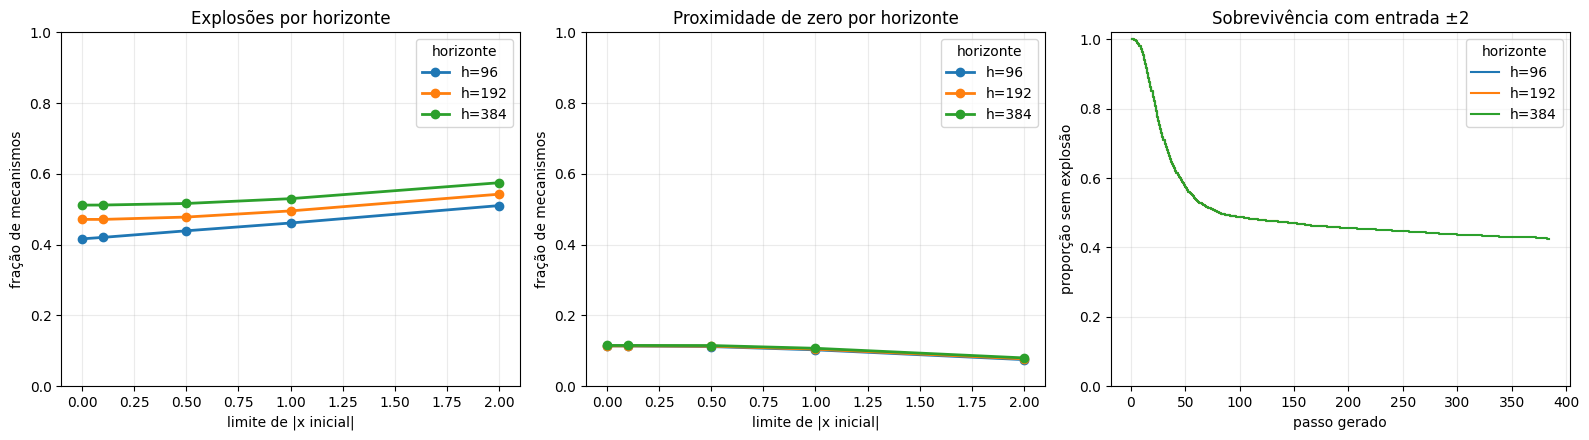

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for horizon, table in horizon_tables.items():
    x = table.index.to_numpy()
    axes[0].plot(x, table["taxa_de_explosão"], marker="o", linewidth=2, label=f"h={horizon}")
    axes[1].plot(x, table["taxa_próximas_de_zero"], marker="o", linewidth=2, label=f"h={horizon}")
axes[0].set(title="Explosões por horizonte", xlabel="limite de |x inicial|", ylabel="fração de mecanismos", ylim=(0, 1))
axes[1].set(title="Proximidade de zero por horizonte", xlabel="limite de |x inicial|", ylabel="fração de mecanismos", ylim=(0, 1))
for axis in axes[:2]:
    axis.legend(title="horizonte"); axis.grid(alpha=0.25)

largest_limit = max(INPUT_ABS_LIMITS)
for horizon in GENERATED_HORIZONS:
    group = simulations[simulations["generated_horizon"].eq(horizon) & simulations["input_abs_limit"].eq(largest_limit)]
    survival = 1.0 - np.asarray([(group["explosion_step"].fillna(np.inf) <= step).mean() for step in range(1, horizon + 1)])
    axes[2].step(range(1, horizon + 1), survival, where="post", label=f"h={horizon}")
axes[2].set(title=f"Sobrevivência com entrada ±{largest_limit:g}", xlabel="passo gerado", ylabel="proporção sem explosão", ylim=(0, 1.02))
axes[2].grid(alpha=0.25); axes[2].legend(title="horizonte")

fig.tight_layout()
plt.show()

## 5. Quais estruturas mais explodem?

As tabelas e gráficos seguintes estratificam o risco por quantidade de multiplicações, complexidade total, número de lags e magnitude máxima dos parâmetros. Isso ajuda a separar o efeito do tamanho da entrada do efeito da gramática.


In [8]:
risk_by_multiplication = reference_simulations.pivot_table(
    index="multiply_count",
    columns="input_abs_limit",
    values="exploded",
    aggfunc=["mean", "size"],
)
risk_by_multiplication

mean                                          size        \
input_abs_limit       0.0       0.1       0.5       1.0       2.0   0.0   0.1   
multiply_count                                                                  
0                0.559224  0.559224  0.559224  0.559224  0.559224  2423  2423   
1                0.440331  0.440884  0.453039  0.484530  0.566851  1810  1810   
2                0.315615  0.315615  0.328904  0.365449  0.478405   602   602   
3                0.102190  0.094891  0.116788  0.160584  0.284672   137   137   
4                0.038462  0.038462  0.038462  0.115385  0.192308    26    26   
5                0.000000  0.000000  0.000000  0.000000  0.000000     2     2   

                                   
input_abs_limit   0.5   1.0   2.0  
multiply_count                     
0                2423  2423  2423  
1                1810  1810  1810  
2                 602   602   602  
3                 137   137   137  
4                  26    26    26  
5                   2     2     2

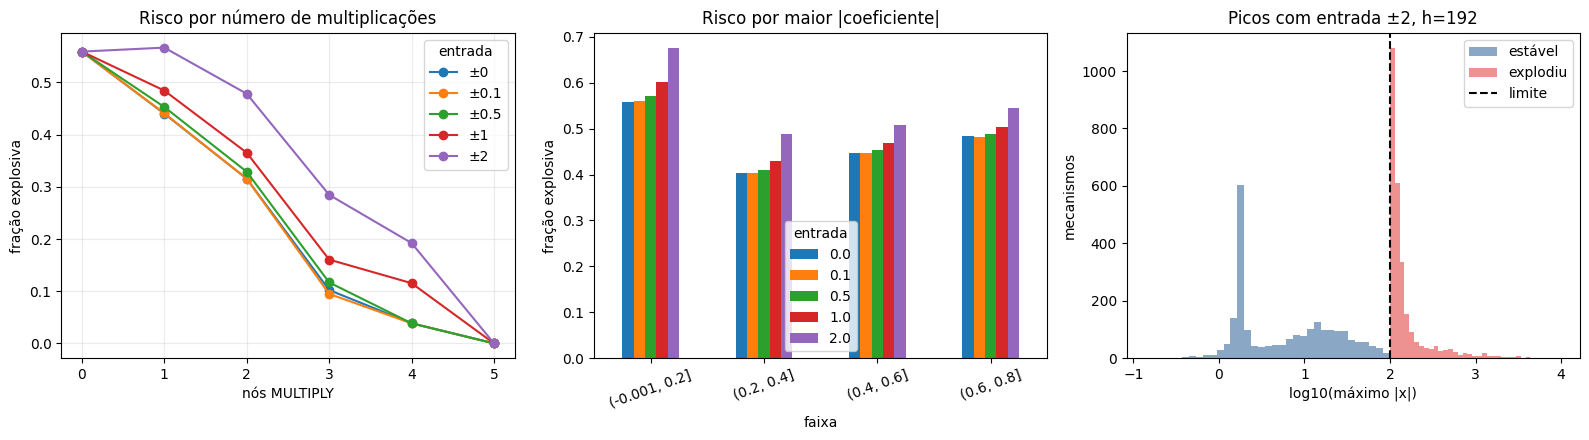

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for limit, group in reference_simulations.groupby("input_abs_limit"):
    grouped = group.groupby("multiply_count")["exploded"].mean()
    axes[0].plot(grouped.index, grouped, marker="o", label=f"±{limit:g}")
axes[0].set(title="Risco por número de multiplicações", xlabel="nós MULTIPLY", ylabel="fração explosiva")
axes[0].legend(title="entrada"); axes[0].grid(alpha=0.25)

parameter_bins = pd.cut(reference_simulations["max_abs_parameter"], bins=[0, .2, .4, .6, .8], include_lowest=True)
parameter_risk = reference_simulations.assign(parameter_bin=parameter_bins).pivot_table(index="parameter_bin", columns="input_abs_limit", values="exploded", aggfunc="mean", observed=True)
parameter_risk.plot.bar(ax=axes[1])
axes[1].set(title="Risco por maior |coeficiente|", xlabel="faixa", ylabel="fração explosiva")
axes[1].tick_params(axis="x", rotation=20); axes[1].legend(title="entrada")

largest_limit = max(INPUT_ABS_LIMITS)
largest = reference_simulations[reference_simulations["input_abs_limit"].eq(largest_limit)]
peak_values = np.log10(np.maximum(largest["peak_abs"].replace(np.inf, EXPLOSION_LIMIT*10), 1e-8))
for exploded, label, color in [(False, "estável", "#4C78A8"), (True, "explodiu", "#E45756")]:
    axes[2].hist(peak_values[largest["exploded"].eq(exploded)], bins=35, alpha=.65, label=label, color=color)
axes[2].axvline(np.log10(EXPLOSION_LIMIT), color="black", linestyle="--", label="limite")
axes[2].set(title=f"Picos com entrada ±{largest_limit:g}, h={REFERENCE_HORIZON}", xlabel="log10(máximo |x|)", ylabel="mecanismos")
axes[2].legend()

fig.tight_layout(); plt.show()

In [10]:
non_monotonic_by_horizon = {}
for horizon, horizon_group in simulations.groupby("generated_horizon"):
    paired = horizon_group.pivot(index="sample_index", columns="input_abs_limit", values="exploded").astype(int)
    non_monotonic_by_horizon[int(horizon)] = int((np.diff(paired.to_numpy(), axis=1) < 0).any(axis=1).sum())

lowest_exploders = reference_simulations[
    reference_simulations["input_abs_limit"].eq(min(INPUT_ABS_LIMITS)) & reference_simulations["exploded"]
].sort_values("explosion_step").head(8)[
    ["sample_index", "formula", "operator_count", "multiply_count", "explosion_step", "peak_abs"]
]

print(f"Classificações não monotônicas por horizonte: {non_monotonic_by_horizon}")
print(f"Explosões mais precoces com entrada inicial zero e horizonte {REFERENCE_HORIZON}:")
lowest_exploders

Classificações não monotônicas por horizonte: {96: 12, 192: 9, 384: 9}
Explosões mais precoces com entrada inicial zero e horizonte 192:


,sample_index,formula,operator_count,multiply_count,explosion_step,peak_abs
33290,2219,(((-0.481453 + x_0(t-1)) + -0.761943) * ((x_0(...,6,2,4.0,264.916245
55310,3687,(0.262506 + (((x_0(t-6) + x_0(t-1)) * (0.38843...,5,1,6.0,115.192976
19895,1326,((x_0(t-1) + ((-0.346466 + (-0.0543717 * -0.61...,5,1,6.0,110.503507
17450,1163,(x_0(t-5) + ((-0.126622 + (-0.663107 + (x_0(t-...,6,0,7.0,106.578659
12635,842,((0.574753 + (((x_0(t-11) + x_0(t-2)) + x_0(t-...,6,1,7.0,145.425586
14405,960,((0.688638 + x_0(t-1)) + (0.74035 + x_0(t-1))),3,0,7.0,176.179386
36065,2404,(0.622245 + (((0.32334 + 0.0851003) + x_0(t-1)...,4,0,7.0,129.365336
45530,3035,(((x_0(t-9) + (x_0(t-1) * (x_0(t-1) + (-0.4729...,6,1,7.0,1251.955568


In [11]:
baseline_limit = min(INPUT_ABS_LIMITS)
baseline_risk = reference_simulations[reference_simulations["input_abs_limit"].eq(baseline_limit)].groupby("multiply_count")["exploded"].agg(["size", "mean"])
largest_limit_risk = reference_simulations[reference_simulations["input_abs_limit"].eq(max(INPUT_ABS_LIMITS))].groupby("multiply_count")["exploded"].agg(["size", "mean"])
reference_summary = horizon_tables[REFERENCE_HORIZON]

print(
    f"No horizonte {REFERENCE_HORIZON}, a taxa total cresceu de {reference_summary.loc[min(INPUT_ABS_LIMITS), 'taxa_de_explosão']:.2%} "
    f"para {reference_summary.loc[max(INPUT_ABS_LIMITS), 'taxa_de_explosão']:.2%}."
)
print(
    f"A taxa de trajetórias próximas de zero variou de "
    f"{reference_summary.loc[min(INPUT_ABS_LIMITS), 'taxa_próximas_de_zero']:.2%} para "
    f"{reference_summary.loc[max(INPUT_ABS_LIMITS), 'taxa_próximas_de_zero']:.2%}."
)
print(
    "A hipótese de maior risco com mais MULTIPLY foi contrariada: "
    f"com entrada zero, árvores sem MULTIPLY explodiram a {baseline_risk.loc[0, 'mean']:.2%}, "
    f"contra {baseline_risk.loc[1:, 'mean'].mean():.2%} na média não ponderada das demais faixas."
)
print(
    "Interpretação: lags aditivos têm coeficiente implícito 1; somá-los repetidamente pode criar "
    "ganho autoregressivo > 1, enquanto produtos frequentemente incluem parâmetros de módulo < 0,8."
)
display(pd.concat({"entrada_zero": baseline_risk, "maior_entrada": largest_limit_risk}, axis=1))

No horizonte 192, a taxa total cresceu de 47.14% para 54.26%.
A taxa de trajetórias próximas de zero variou de 11.38% para 7.74%.
A hipótese de maior risco com mais MULTIPLY foi contrariada: com entrada zero, árvores sem MULTIPLY explodiram a 55.92%, contra 17.93% na média não ponderada das demais faixas.
Interpretação: lags aditivos têm coeficiente implícito 1; somá-los repetidamente pode criar ganho autoregressivo > 1, enquanto produtos frequentemente incluem parâmetros de módulo < 0,8.


entrada_zero           maior_entrada          
                       size      mean          size      mean
multiply_count                                               
0                      2423  0.559224          2423  0.559224
1                      1810  0.440331          1810  0.566851
2                       602  0.315615           602  0.478405
3                       137  0.102190           137  0.284672
4                        26  0.038462            26  0.192308
5                         2  0.000000             2  0.000000

## 6. Further stability tests

Useful next checks include resampling coefficients on a fixed tree, varying the innovation scale, extending the horizon, and estimating sensitivity to the initial history.

## 7. Complete experiment record

The following cell retains configuration, provenance, seeds, metrics, findings, and reproduction instructions.

In [12]:
package_versions = {
    name: importlib.metadata.version(name)
    for name in ["numpy", "pandas", "matplotlib"]
}
explosion_metrics = {
    str(horizon): {
        str(limit): {
            "count": int(row["explosões"]),
            "near_zero_count": int(row["próximas_de_zero"]),
            "constant_within_3_innovations_count": int(row["séries_constantes_em_3_inovações"]),
            "near_zero_rate": float(row["taxa_próximas_de_zero"]),
            "near_zero_rate_among_stable": float(row["taxa_próximas_entre_estáveis"]),
            "rate": float(row["taxa_de_explosão"]),
            "median_explosion_step": None if pd.isna(row["passo_mediano_da_explosão"]) else float(row["passo_mediano_da_explosão"]),
            "wilson_95": [float(row["IC95_inferior"]), float(row["IC95_superior"])],
        }
        for limit, row in table.iterrows()
    }
    for horizon, table in horizon_tables.items()
}
experiment_record = {
    "experiment_id": "abstract_syntax_tree_004_large_scale_stability",
    "status": "executed",
    "research_question": (
        "How often do randomly sampled recurrent ASTs explode as the generation horizon and initial x range change?"
    ),
    "hypothesis": (
        "Explosion risk increases with the generation horizon, initial-value bound, and multiplicative structure."
    ),
    "configuration": {
        "sample_count": SAMPLE_COUNT,
        "generated_horizons": list(GENERATED_HORIZONS),
        "reference_horizon_for_detailed_structure_plots": REFERENCE_HORIZON,
        "innovation_std": INNOVATION_STD,
        "near_zero_definition": {
            "radius_in_innovation_standard_deviations": ZERO_RADIUS_INNOVATION_STDS,
            "absolute_radius": ZERO_RADIUS,
            "required_final_steps_inside_radius": ZERO_TAIL_STEPS,
            "requires_non_exploded_trajectory": True,
        },
        "constant_within_3_innovations_definition": {
            "scope": "all generated values; initial history excluded",
            "criterion": "max(abs(x - mean(x))) <= 3 * innovation_std",
            "maximum_deviation_from_series_mean": ZERO_RADIUS,
            "requires_non_exploded_trajectory": True,
        },
        "input_absolute_limits": list(INPUT_ABS_LIMITS),
        "explosion_limit": EXPLOSION_LIMIT,
        "tree": asdict(TREE_CONFIG),
    },
    "seed_policy": {
        "root_seed": ROOT_SEED,
        "mechanism_seed": "derive_sample_seed(ROOT_SEED, sample_index)",
        "paired_trajectory_seed": "SeedSequence([ROOT_SEED, sample_index, 991])",
        "same_innovations_across_input_limits": True,
        "shorter_horizons_are_prefixes_of_longer_horizons": True,
    },
    "provenance": {
        "implementation": [
            "src/tsfmxai/generators/random_expression.py",
            "src/tsfmxai/generators/trajectory.py",
            "src/tsfmxai/representations/expression.py",
        ],
        "python": sys.version,
        "platform": platform.platform(),
        "packages": package_versions,
    },
    "metrics": {
        "sampling_seconds": sampling_seconds,
        "simulation_seconds": simulation_seconds,
        "outcomes_by_horizon_and_input_limit": explosion_metrics,
        "non_monotonic_explosion_classifications_by_horizon": non_monotonic_by_horizon,
    },
    "scientific_summary": (
        f"At the reference horizon {REFERENCE_HORIZON}, explosion frequency increased from "
        f"{reference_summary.loc[min(INPUT_ABS_LIMITS), 'taxa_de_explosão']:.2%} at zero initial input to "
        f"{reference_summary.loc[max(INPUT_ABS_LIMITS), 'taxa_de_explosão']:.2%} at the largest bound. "
        f"The fraction remaining within three innovation standard deviations of zero for all final {ZERO_TAIL_STEPS} steps "
        f"changed from {reference_summary.loc[min(INPUT_ABS_LIMITS), 'taxa_próximas_de_zero']:.2%} to "
        f"{reference_summary.loc[max(INPUT_ABS_LIMITS), 'taxa_próximas_de_zero']:.2%}. "
        f"Series whose complete generated range stayed within three innovation standard deviations were observed "
        f"{int(explosion_summary['séries_constantes_em_3_inovações'].sum())} times across all horizon-bound runs. "
        "The multiplicative-risk hypothesis was contradicted: additive lag sums dominated explosions because lag leaves have "
        "implicit unit coefficients, while products often introduce sub-unit sampled parameters. Algebraic-shape collisions "

    ),
    "reproduction_command": (
        "python -m jupyter nbconvert --to notebook --execute "
        "experiments/abstract_syntax_tree/4_large_scale_stability.ipynb "
        "--inplace --ExecutePreprocessor.timeout=2400"
    ),
}

print(json.dumps(experiment_record, indent=2, ensure_ascii=False))

{
  "experiment_id": "abstract_syntax_tree_004_large_scale_stability",
  "status": "executed",
  "research_question": "How often do randomly sampled recurrent ASTs explode as the generation horizon and initial x range change?",
  "hypothesis": "Explosion risk increases with the generation horizon, initial-value bound, and multiplicative structure.",
  "configuration": {
    "sample_count": 5000,
    "generated_horizons": [
      96,
      192,
      384
    ],
    "reference_horizon_for_detailed_structure_plots": 192,
    "innovation_std": 0.05,
    "near_zero_definition": {
      "radius_in_innovation_standard_deviations": 3.0,
      "absolute_radius": 0.15000000000000002,
      "required_final_steps_inside_radius": 24,
      "requires_non_exploded_trajectory": true
    },
    "constant_within_3_innovations_definition": {
      "scope": "all generated values; initial history excluded",
      "criterion": "max(abs(x - mean(x))) <= 3 * innovation_std",
      "maximum_deviation_from_seri

**Interpretation.** These rates describe the sampled mechanisms under the stated horizon, threshold, innovation law, and initial-value ranges.